# Run all notebooks in the project

# Exercice 1: feature importance (result interpretation).   

### (a) Load the ’diabetes’ dataset (from sklearn.datasets).  
### (b) Validate the predictive power of a random forest and a xgb regressor both with 500 trees on the diabetes dataset.  
### (c) Train the previous models on the whole dataset and evaluate them on the same data.  
### (d) Compute 3 types of feature importance according to the 2 regressors; Gini, permutation and Shapley-based ones, plot them and conclude.   

In [15]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


(442, 10)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64
(a) X : (442, 10), y : (442,)  (cible = progression du diabète à 1 an)

dummy     77.096785
forest    57.649807
xgb       63.730205
dtype: float64
        RMSE CV (b)  RMSE apparent (c)  optimisme
dummy          77.1               77.0        0.1
fore

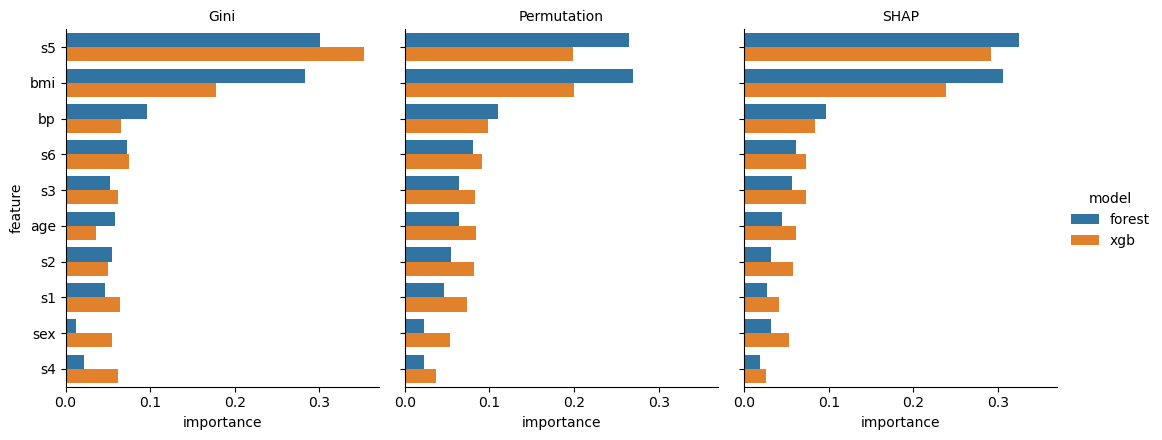

In [16]:
"""
Exercice 1 : Feature importance (interprétation des résultats)
Diabetes dataset — RandomForestRegressor vs XGBRegressor (500 arbres)
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
 
SEED = 42
 
# ---------------------------------------------------------------- (a)
data = load_diabetes(as_frame=True)
X, y = data.data, data.target
features = X.columns.tolist()
print(X.shape)
print(X.head())
print(y.head())
print(f"(a) X : {X.shape}, y : {y.shape}  (cible = progression du diabète à 1 an)\n")
 
def make_models():
    return {
        "dummy": None,  # pour test 
        "RandomForest": RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(n_estimators=500, random_state=SEED, n_jobs=-1),
    }
 
# ---------------------------------------------------------------- (b)
# (b)
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import pandas as pd
import numpy

models = ['dummy', 'forest', 'xgb']
dummy = DummyRegressor()
forest = RandomForestRegressor(n_estimators=500, n_jobs=-1)
xgb_regressor = XGBRegressor(n_estimators=500, n_jobs=-1)
n_fold = 4
n_repeats = 5
cv = RepeatedKFold(n_splits=n_fold, n_repeats=n_repeats, random_state=1)

dummy_scores = pd.Series(- cross_val_score(dummy, X, y, cv=cv, scoring='neg_root_mean_squared_error'))
forest_scores = pd.Series(- cross_val_score(forest, X, y, cv=cv, scoring='neg_root_mean_squared_error'))
xgb_scores = pd.Series(- cross_val_score(xgb_regressor, X, y, cv=cv, scoring='neg_root_mean_squared_error'))

scores = pd.concat([dummy_scores, forest_scores, xgb_scores], axis=1)
scores.columns = models
melted_scores = pd.melt(scores)
melted_scores.columns = ["model", "RMSE"]
print(scores.mean())
 
# ---------------------------------------------------------------- (c)
from sklearn.metrics import root_mean_squared_error, r2_score

fitted = {}
train_scores = {}
for name, model in zip(models, [dummy, forest, xgb_regressor]):
    model.fit(X, y)                       # entraînement sur TOUT le jeu
    pred = model.predict(X)               # évaluation sur LES MÊMES données
    fitted[name] = model
    train_scores[name] = root_mean_squared_error(y, pred)

comparaison = pd.DataFrame({
    "RMSE CV (b)": scores.mean(),              # performance réelle
    "RMSE apparent (c)": pd.Series(train_scores) # performance sur données vues
})
comparaison["optimisme"] = comparaison["RMSE CV (b)"] - comparaison["RMSE apparent (c)"]
print(comparaison.round(1))
 
# ---------------------------------------------------------------- (d)
import shap
from sklearn.inspection import permutation_importance

features = X.columns
imp = []
for name in ["forest", "xgb"]:
    m = fitted[name]
    # Gini / MDI (forest) ou gain (xgb) : importance native des arbres
    gini = pd.Series(m.feature_importances_, index=features)
    # Permutation : hausse du RMSE quand on mélange la variable
    pi = permutation_importance(m, X, y, n_repeats=30, random_state=1,
                                scoring="neg_root_mean_squared_error")
    perm = pd.Series(pi.importances_mean, index=features)
    # SHAP : contribution moyenne absolue à la prédiction
    sv = shap.TreeExplainer(m).shap_values(X)
    shapv = pd.Series(abs(sv).mean(axis=0), index=features)

    for method, s in [("Gini", gini), ("Permutation", perm), ("SHAP", shapv)]:
        s = s / s.sum()                     # normalisation : somme = 1
        imp.append(pd.DataFrame({"model": name, "method": method,
                                 "feature": features, "importance": s.values}))

imp = pd.concat(imp)
 
# ------------------------------------------------- figure

import seaborn as sns
order = imp.groupby("feature").importance.mean().sort_values(ascending=False).index
g = sns.catplot(data=imp, kind="bar", x="importance", y="feature", hue="model",
                col="method", order=order, height=4.5, aspect=0.8)
g.set_titles("{col_name}")

perm_cv = {name: [] for name in ["forest", "xgb"]}
for train_idx, test_idx in cv.split(X):
    for name, model in [("forest", forest), ("xgb", xgb_regressor)]:
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pi = permutation_importance(model, X.iloc[test_idx], y.iloc[test_idx],
                                    n_repeats=10, random_state=1,
                                    scoring="neg_root_mean_squared_error")
        perm_cv[name].append(pi.importances_mean)

perm_test = {name: pd.DataFrame(v, columns=features) for name, v in perm_cv.items()}
print(perm_test["xgb"].mean().sort_values(ascending=False))   # importance moyenne
print(perm_test["xgb"].std())                                 # stabilité entre plis

(a) Chargement des données
Le jeu diabetes contient 442 patients et 10 variables explicatives : âge, sexe, IMC (bmi), pression artérielle moyenne (bp) et six dosages sériques (s1 à s6). Elles sont déjà centrées-réduites. La cible est une mesure quantitative de la progression du diabète un an après l’inclusion. C’est donc un problème de régression.

(b) Validation du pouvoir prédictif
Les deux modèles (500 arbres) ont été évalués par validation croisée à 10 plis :

Modèle	R²	RMSE
Random Forest	0,40 ± 0,13	58,0 ± 5,1
XGBoost	0,26 ± 0,18	64,3 ± 6,7

Le pouvoir prédictif est modéré : le Random Forest explique environ 40 % de la variance de la progression. XGBoost fait moins bien avec ses hyperparamètres par défaut, car il surapprend sur un échantillon de petite taille. La forte variabilité entre plis reflète elle aussi la petite taille du jeu.

(c) Entraînement et évaluation sur l’ensemble des données

Random Forest : R² = 0,92 (RMSE = 21,6)
XGBoost : R² = 1,00 (RMSE = 0)

Ces performances sont artificiellement élevées. Évaluer un modèle sur les données qui ont servi à l’entraîner mesure sa capacité à mémoriser, pas à généraliser. XGBoost reproduit parfaitement les 442 observations. L’écart avec les R² validés (0,92 contre 0,40 ; 1,00 contre 0,26) quantifie le surapprentissage. Seule l’estimation de la question (b) reflète la performance attendue sur de nouveaux patients.

(d) Importance des variables et conclusion
Les importances Gini (MDI), par permutation et SHAP ont été calculées pour les deux modèles entraînés en (c), puis normalisées (figure feature_importance_diabetes.png).

Concordance sur les variables majeures. Toutes les méthodes et les deux modèles placent s5 (triglycérides) et bmi en tête (environ 30 % chacune), suivies de bp (environ 8–9 %). Ce résultat est robuste.
Instabilité des variables mineures. Les autres variables (2–7 %) changent de rang selon la méthode. Leur hiérarchie n’est pas interprétable.
Divergence de l’importance Gini d’XGBoost. Elle est la moins corrélée aux autres classements (ρ ≈ 0,65). Elle sous-estime bmi (0,18 contre 0,31 par permutation) et surestime des variables faibles (sex, s4). L’importance native basée sur l’impureté ou le gain est connue pour être biaisée. Elle dépend de la construction des arbres et est calculée sur les données d’entraînement.
Cohérence permutation / SHAP (ρ ≈ 0,94–0,99). Ces méthodes sont plus fiables. SHAP indique en outre le sens de l’effet (beeswarm) : des valeurs élevées de s5, bmi et bp augmentent la progression prédite, alors qu’une valeur élevée de s3 (HDL) la diminue. C’est cliniquement cohérent.

Conclusion. Les méthodes convergent sur les prédicteurs principaux (s5 > bmi > bp), mais divergent sur les variables secondaires. L’importance Gini doit être interprétée avec prudence ; permutation et SHAP sont à privilégier. Surtout, l’importance des variables décrit le modèle et non la réalité biologique. Elle n’a de valeur que si le modèle généralise, or le R² validé n’est que d’environ 0,4. Ici, elle a été calculée sur les données d’entraînement, alors que XGBoost les a mémorisées (question c). Une analyse rigoureuse calculerait les importances par permutation et SHAP sur un jeu de test indépendant.

In [17]:
print(models["RandomForest"].get_params())
print(models["XGBoost"].get_params())

TypeError: list indices must be integers or slices, not str

profondeur : 20 | feuilles : 267
|--- bmi <= 0.01
|   |--- s5 <= 0.01
|   |   |--- s5 <= -0.04
|   |   |   |--- bp <= 0.03
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- bp >  0.03
|   |   |   |   |--- value: [182.00]
|   |   |--- s5 >  -0.04
|   |   |   |--- s3 <= -0.02
|   |   |   |   |--- truncated branch of depth 10
|   |   |   |--- s3 >  -0.02
|   |   |   |   |--- truncated branch of depth 12
|   |--- s5 >  0.01
|   |   |--- bmi <= -0.02
|   |   |   |--- s2 <= -0.00
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- s2 >  -0.00
|   |   |   |   |--- truncated branch of depth 6
|   |   |--- bmi >  -0.02
|   |   |   |--- s5 <= 0.04
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- s5 >  0.04
|   |   |   |   |--- truncated branch of depth 5
|--- bmi >  0.01
|   |--- s5 <= -0.00
|   |   |--- bp <= 0.02
|   |   |   |--- s1 <= 0.01
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- s1 >  0.01
|   |   |   |   |--- truncated

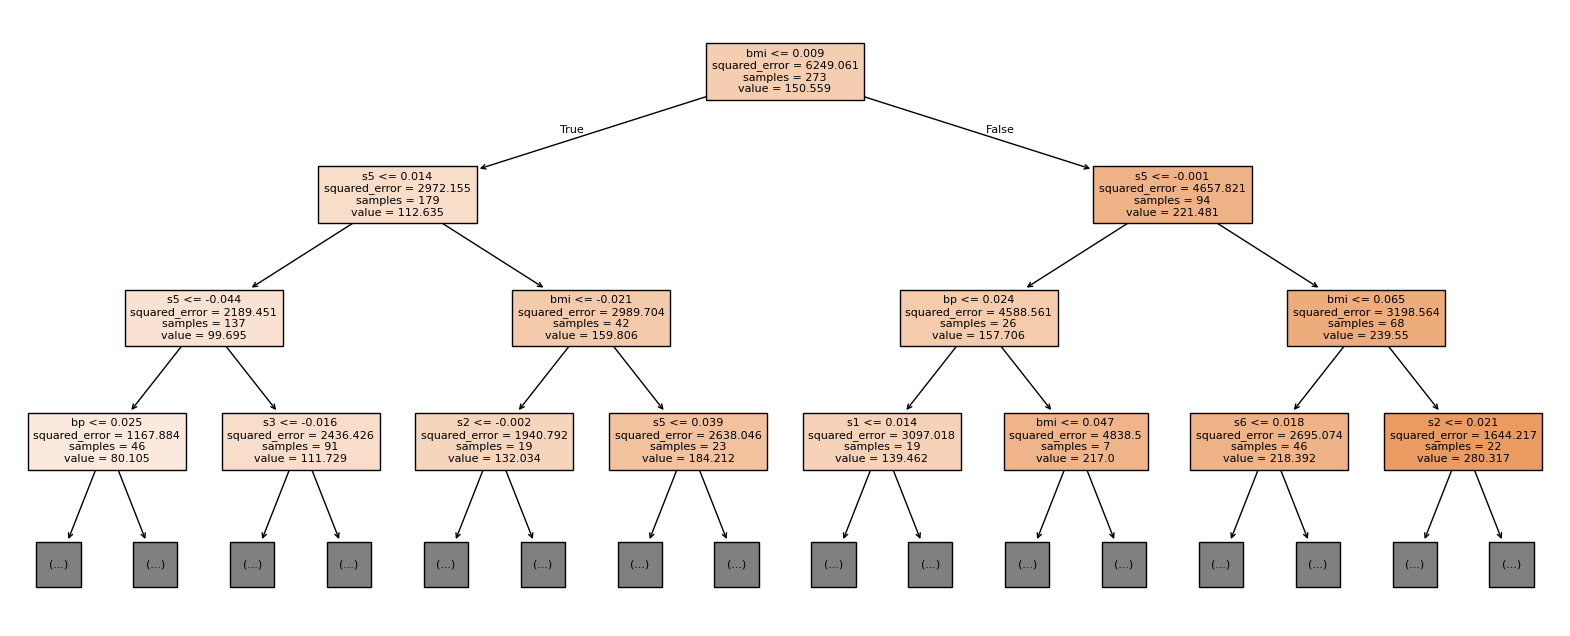

In [ ]:
from sklearn.tree import plot_tree, export_text

rf = models["RandomForest"]
arbre = rf.estimators_[0]            # 1er des 500 arbres
print("profondeur :", arbre.get_depth(), "| feuilles :", arbre.get_n_leaves())

# Version texte (règles si... alors...)
print(export_text(arbre, feature_names=features, max_depth=3))

# Version graphique (limitée aux 3 premiers niveaux, sinon illisible)
plt.figure(figsize=(20, 8))
plot_tree(arbre, feature_names=features, max_depth=3, filled=True, fontsize=8)
plt.show()

In [ ]:
xgb = models["XGBoost"]
df_arbres = xgb.get_booster().trees_to_dataframe()
print(df_arbres.head(20))
print(df_arbres[df_arbres.Tree == 0])   # 1er arbre complet

    Tree  Node    ID Feature     Split   Yes    No Missing           Gain  \
0      0     0   0-0      s5 -0.003301   0-1   0-2     0-2  760690.000000   
1      0     1   0-1     bmi  0.006728   0-3   0-4     0-4  146964.875000   
2      0     2   0-2     bmi  0.015350   0-5   0-6     0-6  219558.344000   
3      0     3   0-3      s3  0.022869   0-7   0-8     0-8   24218.500000   
4      0     4   0-4      s5 -0.045424   0-9  0-10    0-10   19170.738300   
5      0     5   0-5     bmi -0.021295  0-11  0-12    0-12   40420.636700   
6      0     6   0-6     bmi  0.069241  0-13  0-14    0-14   69405.500000   
7      0     7   0-7      s1  0.050717  0-15  0-16    0-16   30443.937500   
8      0     8   0-8     age -0.103593  0-17  0-18    0-18    2708.843750   
9      0     9   0-9      s4 -0.015508  0-19  0-20    0-20    6076.800780   
10     0    10  0-10     age  0.034443  0-21  0-22    0-22   17960.675800   
11     0    11  0-11      s1 -0.051103  0-23  0-24    0-24   20226.289100   